# Probability calibration and reliability

This notebook asks whether saved model probabilities agree with observed resignation frequencies. For example, among employees assigned a score near 0.30, did roughly 30% resign? **Calibration measures probability accuracy; discrimination measures ranking.** A constant score near the 10% base rate can have a good Brier score and still fail to identify which employees resign.

Run All uses the six canonical **development out-of-fold (OOF)** prediction files. It produces reliability tables, probability-error summaries, fold diagnostics and figures. It fits no model or calibrator and does not evaluate the formal holdout. The FT input is the registered fixed-FT02 GPU experiment, not a completed multi-candidate search.

## 1. Setup and validated inputs

Each saved prediction must match its development employee, original target and frozen outer validation fold. An OOF prediction was produced with that employee's outer validation fold excluded from model training. The shared loader checks these boundaries before scoring. All 80,000 assigned development rows are preserved.

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

# Find the project from either its root or this notebook's directory.
ROOT = next((path for path in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             if (path / "configs/analysis_registry.yaml").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Run this notebook from inside the Employee Resignation Prediction project.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.evaluation.inputs import load_group_inputs, load_development_data
from src.evaluation.metrics import calculate_binary_metrics
from src.data.feature_contract import load_feature_contract

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda value: f"{value:.6f}")
contract = load_feature_contract(ROOT / "configs/feature_contract.yaml")

In [2]:
# Validate IDs, source labels, frozen fold assignments and probability ranges.
# EBM additionally verifies the formal artifact manifest. No fallback is used.
registry, frames = load_group_inputs(ROOT)
expected_models = {"FT-Transformer", "CatBoost", "XGBoost", "LightGBM", "EBM", "TabNet"}
if set(frames) != expected_models:
    raise ValueError("Exactly the six canonical headline models are required.")
reference = next(iter(frames.values()))
for model, frame in frames.items():
    if not np.array_equal(frame.Employee_ID, reference.Employee_ID):
        raise ValueError(f"{model}: development IDs are not aligned.")
    if not np.array_equal(frame.y_true, reference.y_true):
        raise ValueError(f"{model}: development targets are not aligned.")
prevalence = float(reference.y_true.mean())
display(pd.DataFrame([{"model": name, "rows": len(frame), "folds": frame.cv_fold.nunique(),
                       "input": registry["models"][name]["oof_path"]}
                      for name, frame in frames.items()]))
display(reference.y_true.value_counts().sort_index().rename_axis("Resigned").to_frame("rows"))
print(f"Positive prevalence: {prevalence:.2%}. Original class imbalance retained; no resampling or training here.")

Rows before/after development isolation: 100,000 -> 80,000; Resigned prevalence=0.10010 (imbalanced; no resampling during saved review).


,model,rows,folds,input
0,FT-Transformer,80000,5,results/models/ft_transformer/strict_nested/oo...
1,CatBoost,80000,5,results/models/catboost/oof_predictions.csv
2,XGBoost,80000,5,results/models/xgboost/oof_predictions.csv
3,LightGBM,80000,5,results/models/lightgbm/strict_nested/oof_pred...
4,EBM,80000,5,results/models/ebm/individual_IT25100429/oof_p...
5,TabNet,80000,5,results/models/tabnet/oof_predictions.csv


,rows
Resigned,
0,71992
1,8008


Positive prevalence: 10.01%. Original class imbalance retained; no resampling or training here.


## 2. Probability accuracy and no-skill reference

**Brier score** is the mean squared difference between a probability and its 0/1 outcome; smaller is better. **Expected Calibration Error (ECE)** groups scores into ten equal-width bins and averages the absolute difference between mean score and observed rate, weighted by bin size. ECE depends on binning and can hide problems in sparse bins.

The constant development-prevalence score is a descriptive reference, not an independently trained predictor. Its Brier score is prevalence × (1 − prevalence). Brier skill is `1 − model Brier / reference Brier`; a negative value is worse than this constant reference. Mean score minus prevalence summarizes overall over/underestimation but does not measure individual ranking.

In [3]:
from src.evaluation.calibration import reliability_table, expected_calibration_error

N_BINS = 10
reference_brier = prevalence * (1 - prevalence)
rows, fold_rows, reliability = [], [], {}
for model, frame in frames.items():
    y = frame.y_true.to_numpy(dtype=int)
    probability = frame.y_probability.to_numpy(dtype=float)
    metrics = calculate_binary_metrics(y, probability)
    table = reliability_table(y, probability, N_BINS)
    table.insert(0, "model", model)
    assert table["count"].sum() == len(frame)
    assert np.isclose(table.fraction.sum(), 1)
    reliability[model] = table
    rows.append({
        "model": model, "brier_score": metrics["brier_score"],
        "ece_10_bins": expected_calibration_error(y, probability, N_BINS),
        "mean_probability": float(probability.mean()), "observed_prevalence": prevalence,
        "mean_probability_gap": float(probability.mean()) - prevalence,
        "reference_brier": reference_brier,
        "brier_skill_vs_constant_prevalence": 1 - metrics["brier_score"] / reference_brier,
        "pooled_average_precision": metrics["average_precision"], "pooled_roc_auc": metrics["roc_auc"],
        "occupied_bins": int((table["count"] > 0).sum()),
    })
    # Fold summaries reveal variation hidden by pooled probability diagnostics.
    for fold, subset in frame.groupby("cv_fold", sort=True):
        fold_metrics = calculate_binary_metrics(subset.y_true, subset.y_probability)
        fold_rows.append({"model": model, "cv_fold": int(fold), "rows": len(subset),
                          "brier_score": fold_metrics["brier_score"],
                          "ece_10_bins": expected_calibration_error(subset.y_true, subset.y_probability),
                          "mean_probability": float(subset.y_probability.mean()),
                          "observed_prevalence": float(subset.y_true.mean())})
summary = pd.DataFrame(rows).sort_values(["brier_score", "model"]).reset_index(drop=True)
fold_summary = pd.DataFrame(fold_rows)
display(summary)
display(fold_summary.groupby("model")[["brier_score", "ece_10_bins"]].agg(["mean", "std"]))
print(f"Constant prevalence reference: probability={prevalence:.6f}; Brier={reference_brier:.6f}.")

,model,brier_score,ece_10_bins,mean_probability,observed_prevalence,mean_probability_gap,reference_brier,brier_skill_vs_constant_prevalence,pooled_average_precision,pooled_roc_auc,occupied_bins
0,CatBoost,0.090102,0.003668,0.100098,0.100100,-0.000002,0.090080,-0.000239,0.099860,0.499605,2
1,EBM,0.090109,0.003337,0.100090,0.100100,-0.000010,0.090080,-0.000322,0.099000,0.495976,2
2,FT-Transformer,0.153086,0.162174,0.256567,0.100100,0.156467,0.090080,-0.699446,0.098648,0.497980,4
3,XGBoost,0.175329,0.227166,0.324106,0.100100,0.224006,0.090080,-0.946369,0.101181,0.502471,7
4,LightGBM,0.180215,0.234650,0.331255,0.100100,0.231155,0.090080,-1.000615,0.100153,0.498740,8
5,TabNet,0.186177,0.240548,0.337472,0.100100,0.237372,0.090080,-1.066800,0.099965,0.499317,10


brier_score          ece_10_bins         
                      mean      std        mean      std
model                                                   
CatBoost          0.090102 0.000012    0.003668 0.001648
EBM               0.090109 0.000014    0.003599 0.001905
FT-Transformer    0.153086 0.086255    0.162213 0.213836
LightGBM          0.180215 0.082634    0.234653 0.206616
TabNet            0.186177 0.087553    0.240576 0.208110
XGBoost           0.175329 0.077836    0.227204 0.200321

Constant prevalence reference: probability=0.100100; Brier=0.090080.


## 3. Reliability curves and bin occupancy

Points on the diagonal indicate agreement between scores and outcomes. A point below it means the average predicted probability exceeds the observed rate. Empty bins keep missing means and are omitted from the line. The second figure shows each bin's population share; a curve based on a small fraction of employees should not be overinterpreted. Lines connect summaries, not fitted calibration functions.

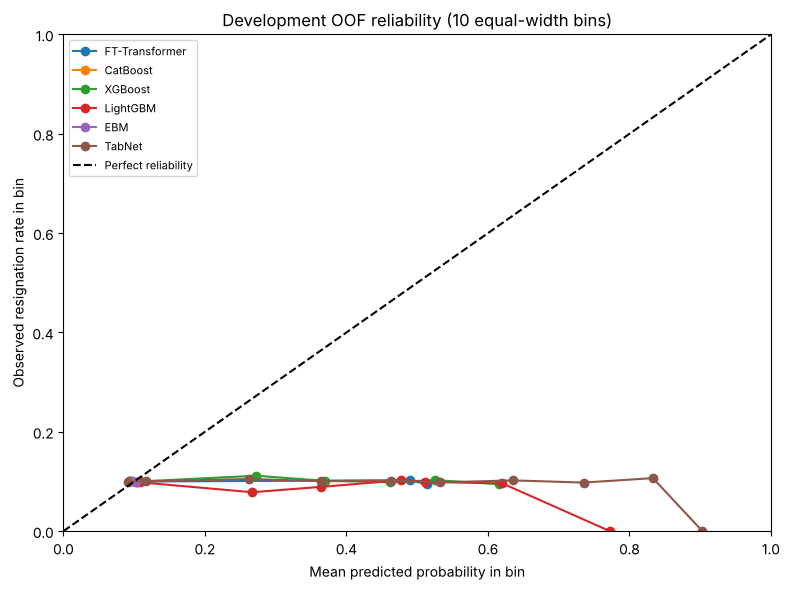

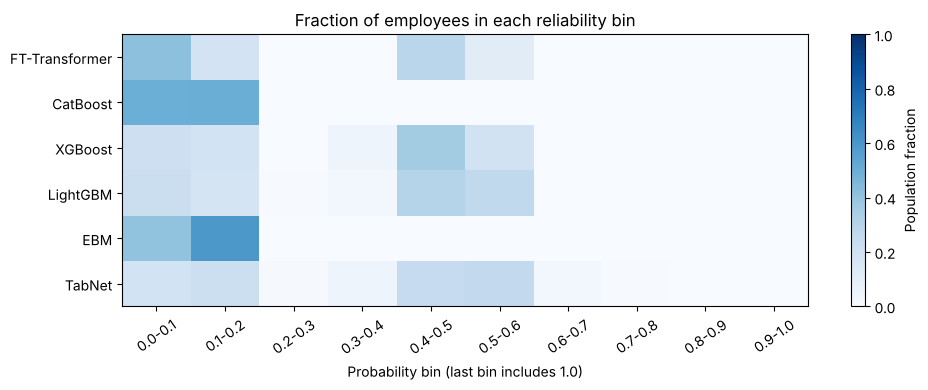

,model,bin,lower,upper,count,mean_probability,observed_rate,fraction
0,FT-Transformer,0,0.000000,0.100000,33415,0.093393,0.100224,0.417687
1,FT-Transformer,1,0.100000,0.200000,14585,0.103978,0.099829,0.182312
4,FT-Transformer,4,0.400000,0.500000,22993,0.489615,0.102422,0.287413
5,FT-Transformer,5,0.500000,0.600000,9007,0.514088,0.094149,0.112587
10,CatBoost,0,0.000000,0.100000,39785,0.096976,0.100666,0.497312
11,CatBoost,1,0.100000,0.200000,40215,0.103186,0.099540,0.502687
20,XGBoost,0,0.000000,0.100000,17003,0.092723,0.100159,0.212537
21,XGBoost,1,0.100000,0.200000,14998,0.108214,0.100013,0.187475
22,XGBoost,2,0.200000,0.300000,278,0.272527,0.111511,0.003475
23,XGBoost,3,0.300000,0.400000,3832,0.368976,0.101253,0.047900


In [4]:
out = ROOT / "results/calibration"
out.mkdir(parents=True, exist_ok=True)
fig, ax = plt.subplots(figsize=(8, 6))
for model, table in reliability.items():
    occupied = table.loc[table["count"] > 0]
    ax.plot(occupied.mean_probability, occupied.observed_rate, marker="o", label=model)
ax.plot([0, 1], [0, 1], "k--", label="Perfect reliability")
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="Mean predicted probability in bin",
       ylabel="Observed resignation rate in bin", title="Development OOF reliability (10 equal-width bins)")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(out / "figure_01_reliability_comparison.png", dpi=160)
plt.show()
plt.close(fig)

occupancy = pd.DataFrame({model: table.fraction.to_numpy() for model, table in reliability.items()}).T
fig, ax = plt.subplots(figsize=(10, 4))
image = ax.imshow(occupancy.to_numpy(), aspect="auto", vmin=0, vmax=1, cmap="Blues")
ax.set_yticks(range(len(occupancy)), occupancy.index)
ax.set_xticks(range(N_BINS), [f"{i/10:.1f}-{(i+1)/10:.1f}" for i in range(N_BINS)], rotation=35)
ax.set(xlabel="Probability bin (last bin includes 1.0)", title="Fraction of employees in each reliability bin")
fig.colorbar(image, ax=ax, label="Population fraction")
fig.tight_layout()
fig.savefig(out / "figure_02_bin_occupancy.png", dpi=160)
plt.show()
plt.close(fig)
display(pd.concat(reliability.values(), ignore_index=True).loc[lambda table: table["count"] > 0])

## 4. Calibration decision and limitations

The current comparison freezes no final predictive model. We therefore complete **raw-score diagnostics** and defer calibrator selection. A sigmoid or isotonic calibrator would require development-only assessment with calibration training and evaluation separated. Fitting and assessing a calibrator on these same outcomes would overstate improvement. A rigorous nested design must also prevent the underlying models from indirectly using calibration-validation labels.

Weighted loss functions can shift probability scales. This notebook describes the registered outputs; it does not establish a controlled causal comparison of weighted versus unweighted training. Good probability error alone cannot rescue near-no-skill discrimination, and raw risk × proxy scores in the next simulation must be labelled exploratory.

In [5]:
best = summary.iloc[0]
decision = {
    "calibration_model_frozen": False, "probability_source_frozen": False,
    "calibrator_fitted": False, "diagnostics_complete": True,
    "development_rows": len(reference), "formal_holdout_accessed": False,
    "best_raw_brier_model": str(best.model),
    "conclusion": "Raw OOF diagnostics are complete. No calibrator or probability source is frozen because the final model is not frozen and discrimination remains near no-skill.",
}
display(Markdown(
    f"**{best.model} has the lowest raw Brier score ({best.brier_score:.6f}).** "
    f"The constant-prevalence reference is {reference_brier:.6f}; its Brier skill is "
    f"{best.brier_skill_vs_constant_prevalence:.4f}. This does not establish useful employee ranking. "
    "No calibration method is selected and the formal holdout remains locked."
))
display(pd.DataFrame([decision]))

**CatBoost has the lowest raw Brier score (0.090102).** The constant-prevalence reference is 0.090080; its Brier skill is -0.0002. This does not establish useful employee ranking. No calibration method is selected and the formal holdout remains locked.

,calibration_model_frozen,probability_source_frozen,calibrator_fitted,diagnostics_complete,development_rows,formal_holdout_accessed,best_raw_brier_model,conclusion
0,False,False,False,True,80000,False,CatBoost,Raw OOF diagnostics are complete. No calibrato...


## 5. Export and completion checks

Save only aggregate diagnostics. Re-read every table and the decision JSON to verify the exports. Empty reliability bins are intentionally missing in CSV; they are not zero observations. Model training files are left intact.

In [6]:
def save_verified_table(frame, path):
    """Export an aggregate table and verify its values survive the CSV round trip."""
    frame.to_csv(path, index=False)
    saved = pd.read_csv(path)
    pd.testing.assert_frame_equal(saved, frame.reset_index(drop=True), check_dtype=False,
                                  rtol=1e-10, atol=1e-12)


def save_verified_json(document, path):
    """Reject non-finite JSON values and confirm a readable, exact round trip."""
    path.write_text(json.dumps(document, indent=2, allow_nan=False), encoding="utf-8")
    assert json.loads(path.read_text(encoding="utf-8")) == document

In [7]:
save_verified_table(summary, out / "calibration_summary.csv")
save_verified_table(fold_summary, out / "calibration_fold_metrics.csv")
for model, table in reliability.items():
    filename = model.lower().replace("-", "_").replace(" ", "_") + "_reliability.csv"
    save_verified_table(table, out / filename)
save_verified_json(decision, out / "calibration_decision.json")
assert len(summary) == 6 and len(fold_summary) == 30
assert all(table["count"].sum() == len(reference) for table in reliability.values())
print("Complete: six-model probability diagnostics and exports verified; no calibrator trained or holdout evaluated.")

Complete: six-model probability diagnostics and exports verified; no calibrator trained or holdout evaluated.
